# Fuzzy steering control for a vehicle in a roundabout

A Mamdani fuzzy controller adds a steering correction SC to the ideal angle `atan(L/R)` so that a car (bicycle model, first-order steering actuator) stays on a circle of radius R, driving counter-clockwise.
Inputs: lateral deviation LD = r − R, an angle error ANG and the LD rate. `ERROR_MODE` picks the angle error: `'steer'` uses δ_actual − δ_ideal, `'heading'` uses ψ − ψ_ref.

Run all cells. The simulations take a few minutes.

In [ ]:
%pip install -q scikit-fuzzy

In [2]:
# ===================== FUZZY ROUNDABOUT CONTROLLER =====================

import math
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Choose the angle error fed to fuzzy
ERROR_MODE = 'steer'   # 'steer' or 'heading'

# ===================================== Helpers =====================================

def clamp(x, a, b):
    return a if x < a else b if x > b else x

def wrap_pi(a):
    return (a + math.pi) % (2 * math.pi) - math.pi

def ld_guard(ld, half_width, max_width=8.0, step=0.5):
    """
    Adaptive LD universe, but quantized so it only takes discrete values.
    This avoids tiny changes that would trigger rebuilds every timestep.
    """
    m_raw = max(half_width, min(max_width, 1.25 * abs(ld) + 0.5))
    m = step * round(m_raw / step)  # e.g., 0.5 m steps
    return clamp(ld, -m, +m), float(m)

def wpe_universe_asymmetric(delta_ideal_deg, steer_min, steer_max, min_each_side=6.0):
    """
    WPE (wheel-plane error) universe around 0:
      WPE = δ_actual − δ_ideal  (0 is ideal).
    The span on each side of 0 is capped at min_each_side (default 6°), or less
    if the steering limits leave less room. This keeps the Neg/Zero/Pos sets
    narrow enough to resolve small errors.
    """
    raw_min = steer_min - delta_ideal_deg
    raw_max = steer_max - delta_ideal_deg
    if raw_min < 0.0 < raw_max:
        ang_min = max(raw_min, -min_each_side)
        ang_max = min(raw_max, +min_each_side)
    else:
        ang_min, ang_max = raw_min, raw_max
    if ang_max <= ang_min:
        ang_min, ang_max = raw_min, raw_max
    return float(ang_min), float(ang_max)

# ===================================== Config =====================================

@dataclass
class Config:
    # Controller/plant/shared
    road_half_width: float = 2.0          # nominal LD half-width (adaptive guard expands as needed)
    steer_min: float = -18.0
    steer_max: float = +18.0
    zero_deadband: float = 2.0            # half-width of the triangular SC 'Zero' set [deg]
    sc_gain_heading: float = 0.25         # only used if ERROR_MODE == 'heading'
    sc_gain_steer: float   = 1.0          # steer mode returns SC directly (SC universe is ±8°)
    error_mode: str = ERROR_MODE          # 'steer' or 'heading'
    he_range: float = 20.0                # heading-error universe half-span [deg]
    ldr_range: float = 0.8                # LD_rate clamp/universe [m/s] (tighter = more damping)

    # Simulation
    R: float = 20.0                       # circle radius [m]
    L: float = 2.8                        # wheelbase [m]
    v: float = 6.0                        # speed [m/s]
    dt: float = 0.02                      # time step [s]
    t_final: float = 60.0                # sim duration [s]
    tau_steer: float = 0.25               # actuator time constant [s] (a bit faster for better damping)

# ================================== Controller ===================================

class RoundaboutFuzzyController:
    """
    Outputs Steering Correction SC [deg]. Command: δ_cmd = δ_ideal + SC

    Inputs:
        LD [m]       : radial deviation (r − R; + outside / − inside)
        ANG [deg]    : 'heading' => ψ − ψ_ref  |  'steer' => δ_actual − δ_ideal  (WPE)
        LDR [m/s]    : LD rate (Out=+; In=−)
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        self._ctrlsys = None
        self._sim = None
        self._LD = self._ANG = self._LDR = self._SC = None
        self._last_universes = None  # cache (ld_half_width, ang_min, ang_max)
        self.fallbacks = 0           # steps where no rule fired and SC was set to 0

    def _build_system(self, ld_half_width, ang_min, ang_max):
        # Universes
        ld_univ  = np.linspace(-ld_half_width, +ld_half_width, 501)
        ang_univ = np.linspace(ang_min, ang_max, 501)
        ldr_univ = np.linspace(-self.cfg.ldr_range, +self.cfg.ldr_range, 401)

        # IMPORTANT: modest SC range to avoid bang-bang; we return SC unscaled in steer mode
        sc_univ  = np.linspace(-8.0, +8.0, 801)

        # Antecedents/Consequent
        LD  = ctrl.Antecedent(ld_univ,  'LD')
        ANG = ctrl.Antecedent(ang_univ, 'ANG')
        LDR = ctrl.Antecedent(ldr_univ, 'LDR')
        SC  = ctrl.Consequent(sc_univ,  'SC')
        SC.defuzzify_method = 'centroid'

        # LD membership (wide middle)
        m = ld_half_width
        LD['Left']   = fuzz.trapmf(ld_univ,  [-m, -m, -0.70*m, -0.25*m])
        LD['Middle'] = fuzz.trimf(ld_univ,   [-0.45*m, 0.0, +0.45*m])
        LD['Right']  = fuzz.trapmf(ld_univ,  [+0.25*m, +0.70*m, +m, +m])

        # ANG membership
        span = (ang_max - ang_min)
        z = min(2.5, 0.25*span)  # ~±2–2.5°
        if self.cfg.error_mode == 'heading':
            # For heading mode, use a softer dead-zone to avoid tiny kicks
            z = min(3.0, 0.30*span)
            ANG['Neg']  = fuzz.trapmf(ang_univ, [ang_min, ang_min, -z, -0.0])
            ANG['Zero'] = fuzz.trapmf(ang_univ,  [-1.0*z, -0.35*z, 0.35*z, 1.0*z])
            ANG['Pos']  = fuzz.trapmf(ang_univ, [0.0, +z, ang_max, ang_max])
        else:
            ANG['Neg']  = fuzz.trapmf(ang_univ, [ang_min, ang_min, -z, 0.0])
            ANG['Zero'] = fuzz.trimf(ang_univ,  [-z, 0.0, +z])
            ANG['Pos']  = fuzz.trapmf(ang_univ, [0.0, +z, ang_max, ang_max])

        # LD_rate membership: In (toward center), Flat, Out (away)
        r = self.cfg.ldr_range; d = 0.22 * r
        LDR['In']   = fuzz.trapmf(ldr_univ, [-r, -r, -0.45*r, 0.0])
        LDR['Flat'] = fuzz.trimf(ldr_univ,  [-d, 0.0, +d])
        LDR['Out']  = fuzz.trapmf(ldr_univ, [0.0, +0.45*r, +r, +r])

        # SC output sets (±8° span; zero dead-band z0)
        s = 8.0; z0 = self.cfg.zero_deadband
        SC['Right']     = fuzz.trapmf(sc_univ, [-s, -s, -0.60*s, -0.35*s])
        SC['HalfRight'] = fuzz.trimf(sc_univ,  [-0.45*s, -0.25*s, -0.05*s])
        SC['Zero']      = fuzz.trimf(sc_univ,  [-z0, 0.0, +z0])
        SC['HalfLeft']  = fuzz.trimf(sc_univ,  [+0.05*s, +0.25*s, +0.45*s])
        SC['Left']      = fuzz.trapmf(sc_univ, [+0.35*s, +0.60*s, +s, +s])

        # ----------------------------- RULES (clean, non-duplicated) -----------------------------
        rules = []

        # Calm when everything is near perfect
        rules += [ctrl.Rule(LD['Middle'] & ANG['Zero'] & LDR['Flat'], SC['Zero'])]

        # Near center: rate-based micro-corrections (avoid using ANG here to kill tiny kicks)
        rules += [ctrl.Rule(LD['Middle'] & LDR['Out'], SC['HalfLeft'])]   # drifting outward → steer in
        rules += [ctrl.Rule(LD['Middle'] & LDR['In'],  SC['HalfRight'])]  # drifting inward  → steer out

        # Far from center: LD dominates; rate modulates strength
        rules += [ctrl.Rule(LD['Right'] & LDR['Out'],  SC['Left'])]
        rules += [ctrl.Rule(LD['Right'] & LDR['Flat'], SC['HalfLeft'])]
        rules += [ctrl.Rule(LD['Right'] & LDR['In'],   SC['HalfLeft'])]

        rules += [ctrl.Rule(LD['Left']  & LDR['In'],   SC['Right'])]
        rules += [ctrl.Rule(LD['Left']  & LDR['Flat'], SC['HalfRight'])]
        rules += [ctrl.Rule(LD['Left']  & LDR['Out'],  SC['HalfRight'])]

        # Cross-coupling (persistent directional error): only when rate ~ 0
        rules += [ctrl.Rule(LD['Right'] & ANG['Neg'] & LDR['Flat'], SC['Left'])]   # outside & under-steering
        rules += [ctrl.Rule(LD['Left']  & ANG['Pos'] & LDR['Flat'], SC['Right'])]  # inside  & over-steering
        # -----------------------------------------------------------------------------------------

        system = ctrl.ControlSystem(rules)
        self._sim = ctrl.ControlSystemSimulation(system)
        self._LD, self._ANG, self._LDR, self._SC = LD, ANG, LDR, SC
        self._ctrlsys = system
        self._last_universes = (ld_half_width, ang_min, ang_max)

    def _maybe_rebuild(self, ld_half_width, ang_min, ang_max):
            if self._ctrlsys is None:
                self._build_system(ld_half_width, ang_min, ang_max)
                return
            old_ld, old_min, old_max = self._last_universes
            # Rebuild when the (0.5 m-quantized) LD width or the ANG range changes
            if ld_half_width != old_ld or ang_min != old_min or ang_max != old_max:
                self._build_system(ld_half_width, ang_min, ang_max)


    def infer(self, ld_m, ldr_ms, angle_err_deg, delta_ideal_deg):
        # 1) LD clamp/universe (adaptive)
        ld_used, ld_half_width = ld_guard(ld_m, self.cfg.road_half_width)

        # 2) ANG universe + mode gain
        if self.cfg.error_mode == 'steer':
            ang_min, ang_max = wpe_universe_asymmetric(
                delta_ideal_deg, self.cfg.steer_min, self.cfg.steer_max, min_each_side=6.0
            )
            mode_gain = self.cfg.sc_gain_steer
        else:
            ang_min, ang_max = -self.cfg.he_range, +self.cfg.he_range
            mode_gain = self.cfg.sc_gain_heading

        # 3) Ensure system universes match current operating point
        self._maybe_rebuild(ld_half_width, ang_min, ang_max)

        # 4) Clamp inputs
        ang_used = clamp(angle_err_deg, ang_min, ang_max)
        ldr_used = clamp(ldr_ms, -self.cfg.ldr_range, +self.cfg.ldr_range)

        # 5) Fuzzy inference
        self._sim.input['LD']  = float(ld_used)
        self._sim.input['ANG'] = float(ang_used)
        self._sim.input['LDR'] = float(ldr_used)
        # If no rule fires for this input (e.g. LD Middle, LDR Flat, ANG Neg/Pos),
        # scikit-fuzzy cannot defuzzify and raises; we then apply no correction
        # (SC = 0) and count the event so it is visible in the results.
        try:
            self._sim.compute()
            sc_raw = float(self._sim.output.get('SC', 0.0))
        except ValueError:
            sc_raw = 0.0
            self.fallbacks += 1
        if not np.isfinite(sc_raw):
            sc_raw = 0.0
            self.fallbacks += 1

        return mode_gain * sc_raw, (ang_min, ang_max)

# ======================= Visualization / utilities (unchanged logic) =======================

def ensure_built_for_current_op(ctrlr: RoundaboutFuzzyController, cfg: Config):
    ld_half_width = cfg.road_half_width
    delta_ideal_deg = math.degrees(math.atan(cfg.L / cfg.R))
    if cfg.error_mode == 'steer':
        ang_min, ang_max = wpe_universe_asymmetric(
            delta_ideal_deg, cfg.steer_min, cfg.steer_max, min_each_side=6.0
        )
    else:
        ang_min, ang_max = -cfg.he_range, +cfg.he_range
    ctrlr._maybe_rebuild(ld_half_width, ang_min, ang_max)

def plot_memberships(ctrlr: RoundaboutFuzzyController):
    vars_and_names = [
        (ctrlr._LD,  "LD  [m]"),
        (ctrlr._ANG, "ANG [deg]"),
        (ctrlr._LDR, "LDR [m/s]"),
        (ctrlr._SC,  "SC  [deg]"),
    ]
    for var, label in vars_and_names:
        if var is None:
            continue
        plt.figure(figsize=(6.8, 3.2))
        for term_name, term in var.terms.items():
            plt.plot(var.universe, term.mf, label=term_name)
        plt.title(f"Memberships for {label}")
        plt.xlabel(label.split()[0]); plt.ylabel("membership")
        plt.grid(True, alpha=0.3)
        plt.legend(ncol=min(5, len(var.terms)))
        plt.tight_layout(); plt.show()

def dataclass_replace(cfg: Config, **kwargs) -> Config:
    d = cfg.__dict__.copy(); d.update(kwargs); return Config(**d)

def run_sweep_R(R_values, cfg_base: Config):
    rows = []
    plt.figure(figsize=(6.4, 6.0))
    theta = np.linspace(0, 2*np.pi, 600)
    for R in R_values:
        cfg = dataclass_replace(cfg_base, R=R)
        ctrlr = RoundaboutFuzzyController(cfg)
        ensure_built_for_current_op(ctrlr, cfg)
        res = simulate_roundabout(ctrlr, cfg)
        plt.plot(res["x"], res["y"], linewidth=1, label=f"R={R:g} m")
        plt.plot(R*np.cos(theta), R*np.sin(theta), linestyle="--", linewidth=0.7, alpha=0.5)
        ld = res["ld"]
        rows.append((R, float(np.sqrt(np.mean(ld**2))), float(np.max(np.abs(ld))),
                     res["delta"][-1], res["delta_ideal_deg"]))
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.title("Paths for multiple R")
    plt.legend(); plt.tight_layout(); plt.show()
    print(f"{'R [m]':>6} | {'RMS|LD| [m]':>11} | {'Max|LD| [m]':>11} | {'δ_final [deg]':>11} | {'δ_ideal [deg]':>12}")
    print("-"*64)
    for R, rms_ld, max_abs_ld, delta_final, delta_ideal in rows:
        print(f"{R:6.1f} | {rms_ld:11.3f} | {max_abs_ld:11.3f} | {delta_final:11.3f} | {delta_ideal:12.3f}")

# ===================================== Simulation =====================================

def compute_angle_error(mode, delta_actual_deg, delta_ideal_deg, psi, x, y):
    if mode == 'steer':                     # WPE
        return delta_actual_deg - delta_ideal_deg
    psi_ref = math.atan2(y, x) + math.pi/2 # heading error
    return math.degrees(wrap_pi(psi - psi_ref))

def steer_actuator(delta_actual, delta_cmd, dt, tau, limits):
    delta_actual += (delta_cmd - delta_actual) * (dt / tau)
    delta_actual = clamp(delta_actual, limits[0], limits[1])
    return delta_actual

def bicycle_step(x, y, psi, v, L, delta_deg, dt):
    psi += (v / L) * math.tan(math.radians(delta_deg)) * dt
    x   += v * math.cos(psi) * dt
    y   += v * math.sin(psi) * dt
    return x, y, psi

def simulate_roundabout(controller: RoundaboutFuzzyController, cfg: Config,
                        x0=None, y0=None, psi0=None, delta0=None):
    # Initial state (you can pass x0 = cfg.R + d for any d ∈ [-1.5, +1.5])
    if x0 is None:
        x0 = cfg.R + 1.5
    if y0 is None:
        y0 = 0.0
    if psi0 is None:
        psi0 = math.pi / 2
    if delta0 is None:
        delta0 = 0.0

    T = np.arange(0, cfg.t_final + 1e-12, cfg.dt)
    x, y, psi = float(x0), float(y0), float(psi0)
    delta_actual = float(delta0)
    delta_ideal_deg = math.degrees(math.atan(cfg.L / cfg.R))

    xs, ys, psis, deltas, lds, ldrs, errs, scs = [], [], [], [], [], [], [], []
    r0 = math.hypot(x, y)
    ld_prev = r0 - cfg.R

    for _ in T:
        r   = math.hypot(x, y)
        ld  = r - cfg.R
        ldr = (ld - ld_prev) / cfg.dt
        ld_prev = ld

        ang_err_deg = compute_angle_error(controller.cfg.error_mode,
                                          delta_actual, delta_ideal_deg, psi, x, y)
        sc_cmd, _ = controller.infer(ld, ldr, ang_err_deg, delta_ideal_deg)

        delta_cmd = clamp(delta_ideal_deg + sc_cmd, cfg.steer_min, cfg.steer_max)
        delta_actual = steer_actuator(delta_actual, delta_cmd, cfg.dt, cfg.tau_steer,
                                      (cfg.steer_min, cfg.steer_max))

        x, y, psi = bicycle_step(x, y, psi, cfg.v, cfg.L, delta_actual, cfg.dt)

        xs.append(x); ys.append(y); psis.append(psi)
        deltas.append(delta_actual); lds.append(ld); ldrs.append(ldr)
        errs.append(ang_err_deg); scs.append(sc_cmd)

    label = "Heading error (ψ−ψ_ref) [deg]" if controller.cfg.error_mode == 'heading' \
            else "WPE (δ_actual − δ_ideal) [deg]"
    return {
        "t": T, "x": np.array(xs), "y": np.array(ys),
        "psi": np.array(psis), "delta": np.array(deltas),
        "ld": np.array(lds), "ldr": np.array(ldrs),
        "err": np.array(errs), "sc": np.array(scs),
        "R": cfg.R, "delta_ideal_deg": delta_ideal_deg, "err_label": label,
    }

# ============================= Compare 'steer' vs 'heading' (optional) ============================

def _cfg_replace(cfg: Config, **kwargs) -> Config:
    d = cfg.__dict__.copy(); d.update(kwargs); return Config(**d)

def simulate_with_mode(cfg_base: Config, mode: str, x0=None, y0=None, psi0=None, delta0=None):
    cfg = _cfg_replace(cfg_base, error_mode=mode)
    ctrlr = RoundaboutFuzzyController(cfg)
    return simulate_roundabout(ctrlr, cfg, x0=x0, y0=y0, psi0=psi0, delta0=delta0)

def plot_compare_modes(res_steer, res_heading, title_suffix="(same initial state)"):
    plt.figure(figsize=(6.4, 6.0))
    for res, lab in [(res_steer, "steer"), (res_heading, "heading")]:
        R = res["R"]; theta = np.linspace(0, 2*np.pi, 600)
        plt.plot(R*np.cos(theta), R*np.sin(theta), linestyle="--", linewidth=0.7, alpha=0.35)
        plt.plot(res["x"], res["y"], linewidth=1, label=f"path: {lab}")
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.title(f"Path tracking {title_suffix}")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7.2, 3.0))
    plt.plot(res_steer["t"], res_steer["ld"], linewidth=1, label="LD (steer)")
    plt.plot(res_heading["t"], res_heading["ld"], linewidth=1, label="LD (heading)")
    plt.xlabel("time (s)"); plt.ylabel("LD (m)"); plt.title("Lateral Deviation")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7.2, 3.0))
    plt.plot(res_steer["t"], res_steer["sc"], linewidth=1, label="SC (steer)")
    plt.plot(res_heading["t"], res_heading["sc"], linewidth=1, label="SC (heading)")
    plt.xlabel("time (s)"); plt.ylabel("SC (deg)"); plt.title("Steering Correction")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7.2, 3.0))
    plt.plot(res_steer["t"],   res_steer["delta"],   linewidth=1, label="δ_actual (steer)")
    plt.plot(res_heading["t"], res_heading["delta"], linewidth=1, label="δ_actual (heading)")
    plt.axhline(res_steer["delta_ideal_deg"], linestyle="--", linewidth=1, label="δ_ideal")
    plt.xlabel("time (s)"); plt.ylabel("δ (deg)"); plt.title("Steering (actual vs ideal)")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(7.2, 3.0))
    plt.plot(res_steer["t"],   res_steer["err"],   linewidth=1, label=res_steer["err_label"])
    plt.plot(res_heading["t"], res_heading["err"], linewidth=1, label=res_heading["err_label"])
    plt.xlabel("time (s)"); plt.ylabel("angle (deg)"); plt.title("Angle error signal fed to fuzzy")
    plt.legend(); plt.tight_layout(); plt.show()

# ======================================= Plots (wrappers) ======================================

def plot_xy(res):
    theta = np.linspace(0, 2*np.pi, 600); R = res["R"]
    plt.figure(figsize=(6.4,6.0))
    plt.plot(R*np.cos(theta), R*np.sin(theta), label="Target circle", linewidth=1)
    plt.plot(res["x"], res["y"], label="Vehicle path", linewidth=1)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.title("Path tracking")
    plt.legend(); plt.show()

def plot_series(t, y, ylabel, title):
    plt.figure(figsize=(7.2,3.0)); plt.plot(t, y, linewidth=1)
    plt.xlabel("time (s)"); plt.ylabel(ylabel); plt.title(title); plt.show()

def plot_radius(res):
    r_inst = np.sqrt(res["x"]**2 + res["y"]**2)
    plt.figure(figsize=(6.8,3.0))
    plt.plot(res["t"], r_inst); plt.axhline(res["R"], linestyle="--")
    plt.xlabel("time (s)"); plt.ylabel("radius r(t) [m]")
    plt.title("Instantaneous radius vs target"); plt.show()

def plot_all(res):
    plot_xy(res)
    plot_series(res["t"], res["ld"],   "LD (m)",               "Lateral Deviation")
    plot_series(res["t"], res["ldr"],  "LD_rate (m/s)",        "LD rate")
    plot_series(res["t"], res["sc"],   "SC (deg)",             "Steering Correction (fuzzy output × gain)")
    plot_series(res["t"], res["delta"],"δ_actual (deg)",       "Actual Steering Angle")
    plot_series(res["t"], res["err"],  res["err_label"],       "Angle error")
    plot_radius(res)

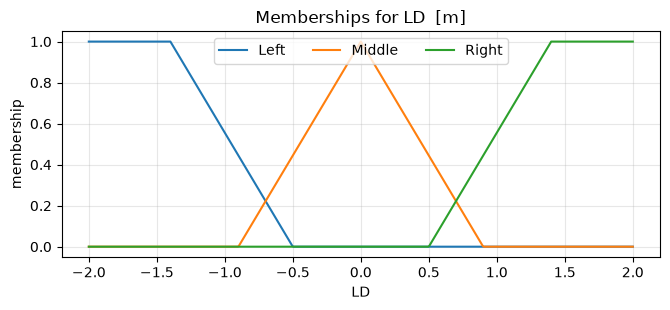

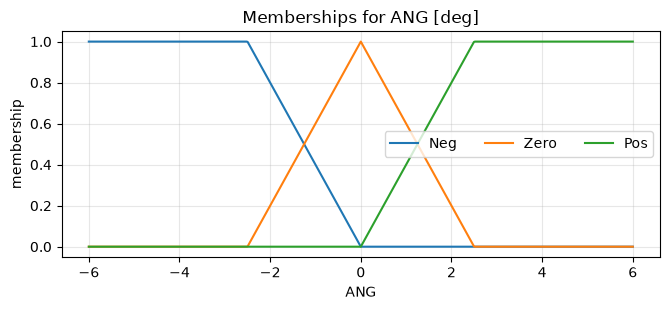

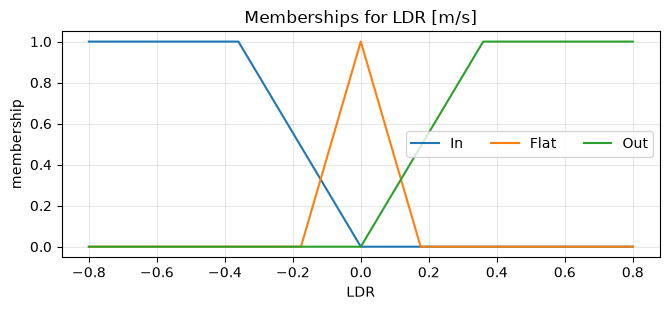

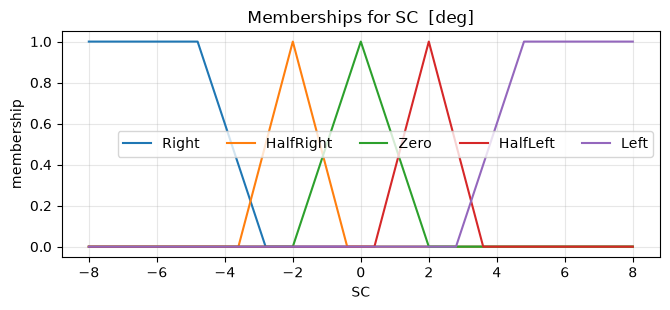

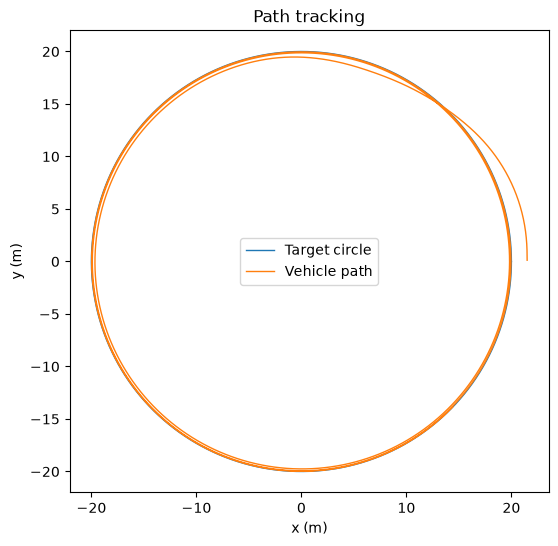

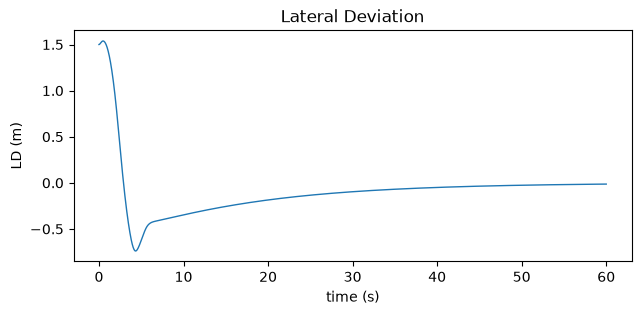

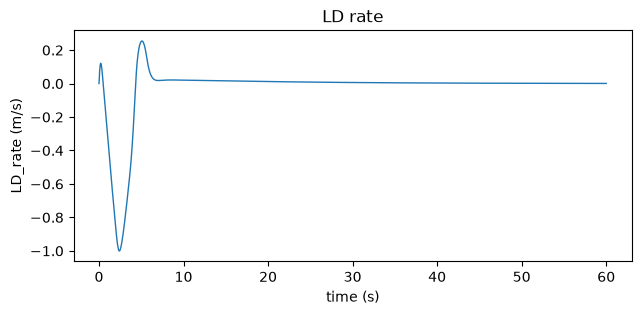

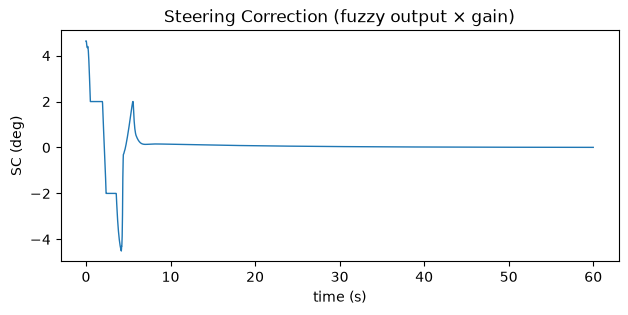

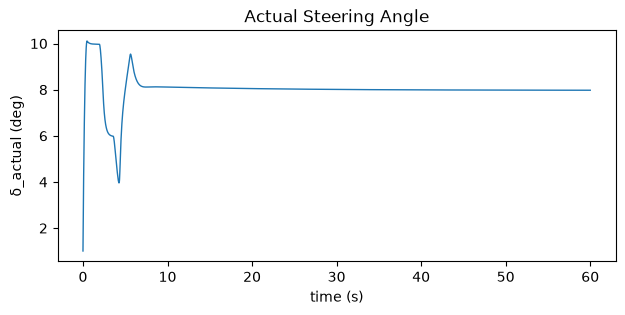

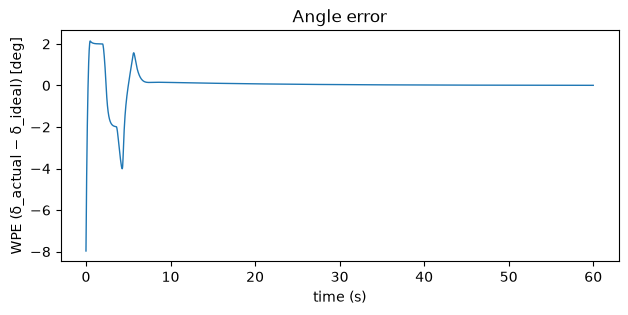

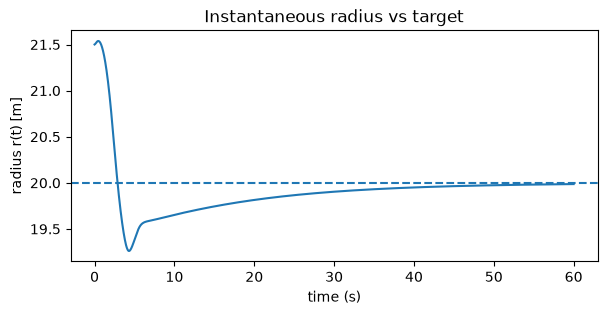

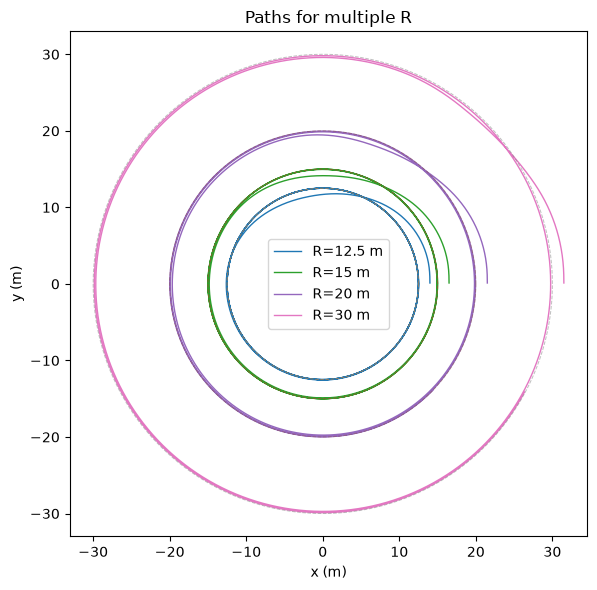

 R [m] | RMS|LD| [m] | Max|LD| [m] | δ_final [deg] | δ_ideal [deg]
----------------------------------------------------------------
  12.5 |       0.297 |       1.577 |      12.626 |       12.626
  15.0 |       0.297 |       1.558 |      10.574 |       10.574
  20.0 |       0.331 |       1.538 |       7.975 |        7.970
  30.0 |       0.368 |       1.516 |       5.350 |        5.332


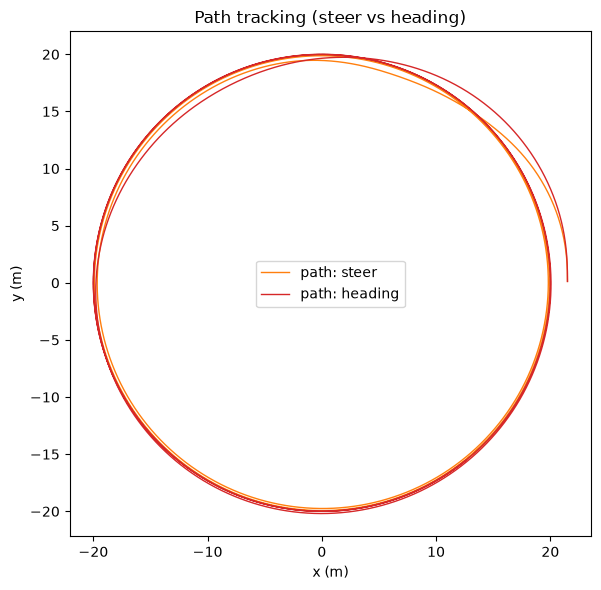

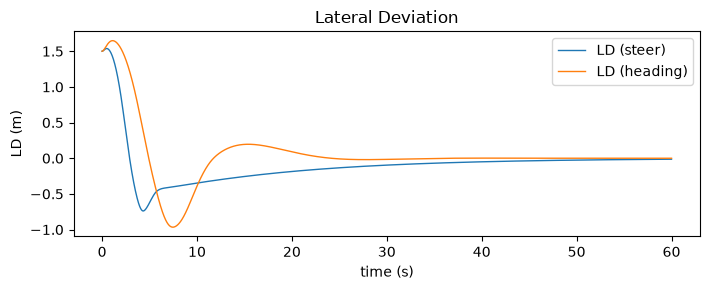

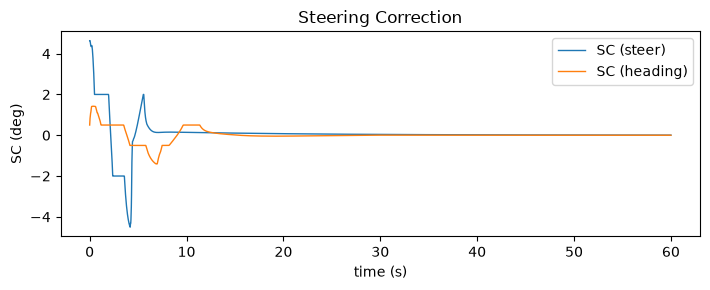

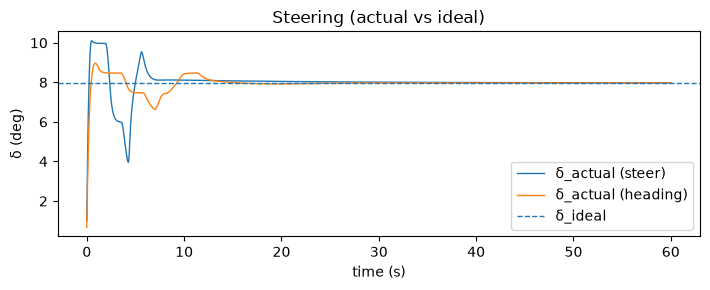

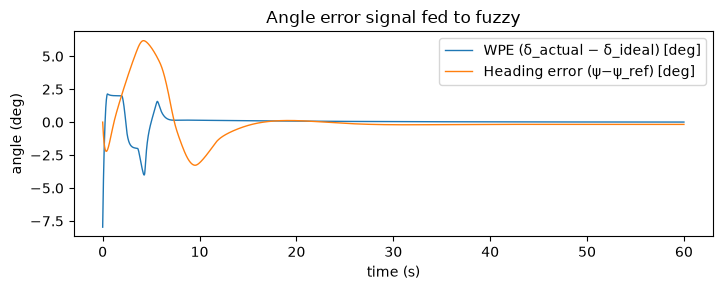

    mode | RMS|LD| [m] | min LD [m] | settle |LD|<=0.1 m | max|SC| [deg]
   steer |       0.331 |     -0.739 |             29.4 s |          4.64
 heading |       0.427 |     -0.966 |             19.7 s |          1.42


In [3]:
# =========================================== Main ===========================================

def settling_time(res, band=0.10):
    """First time after which |LD| stays inside +-band until the end (None if it never does)."""
    outside = np.where(np.abs(res["ld"]) > band)[0]
    if len(outside) == 0:
        return 0.0
    k = outside[-1] + 1
    return float(res["t"][k]) if k < len(res["t"]) else None

def fmt_time(s):
    return "not within run" if s is None else f"{s:.1f} s"

if __name__ == "__main__":
    # Baseline config
    cfg = Config()
    ctrlr = RoundaboutFuzzyController(cfg)

    # Build once and show the membership functions actually used
    ensure_built_for_current_op(ctrlr, cfg)
    plot_memberships(ctrlr)

    # One baseline run (R=20) + plots
    # NOTE: starting conditions come from simulate_roundabout defaults:
    # x0 = R + 1.5 m (LD = +1.5 m), y0 = 0, psi0 = pi/2 (tangent), wheels straight (delta0 = 0).
    res = simulate_roundabout(ctrlr, cfg)
    plot_all(res)

    #Sweep R = 12.5 m, 15 m, 20 m, 30 m (overlay paths + console metrics)
    run_sweep_R([12.5, 15.0, 20.0, 30.0], cfg)

    # Compare 'steer' vs 'heading' with same initial state (uses defaults)
    res_steer   = simulate_with_mode(cfg, "steer")
    res_heading = simulate_with_mode(cfg, "heading")
    plot_compare_modes(res_steer, res_heading, title_suffix="(steer vs heading)")

    print(f"{'mode':>8} | {'RMS|LD| [m]':>11} | {'min LD [m]':>10} | {'settle |LD|<=0.1 m':>18} | {'max|SC| [deg]':>13}")
    for name, r in [("steer", res_steer), ("heading", res_heading)]:
        print(f"{name:>8} | {np.sqrt(np.mean(r['ld']**2)):11.3f} | {r['ld'].min():10.3f} | "
              f"{fmt_time(settling_time(r)):>18} | {np.abs(r['sc']).max():13.2f}")

In [4]:
def plot_ld_sweep(cfg: Config, d_vals, psi_off_deg=0.0, mode="steer",
                  delta0_strategy="zero", trim_first_s=0.0):
    """
    Plot LD(t) for multiple initial lateral deviations d0.
    Shows road limits at ±road_half_width and prints, for every run, the
    extreme LD, whether the car left the lane and the settling time.
    """
    # 1) Local copy of cfg with the requested mode
    cfg_local = dataclass_replace(cfg, error_mode=mode)

    psi0 = math.pi/2 + math.radians(psi_off_deg)
    plt.figure(figsize=(7.2, 3.6))
    rows = []

    for d0 in d_vals:
        x0 = cfg_local.R + float(d0)

        # 2) Always use cfg_local
        ctrlr = RoundaboutFuzzyController(cfg_local)
        ensure_built_for_current_op(ctrlr, cfg_local)

        delta_ideal_deg = math.degrees(math.atan(cfg_local.L / cfg_local.R))
        delta0 = (delta_ideal_deg if delta0_strategy == "ideal" else 0.0)

        res = simulate_roundabout(ctrlr, cfg_local, x0=x0, y0=0.0, psi0=psi0, delta0=delta0)
        rows.append((d0, res["ld"].min(), res["ld"].max(), settling_time(res), ctrlr.fallbacks))

        # trim
        i0 = int(max(0.0, trim_first_s) / cfg_local.dt)
        plt.plot(res["t"][i0:], res["ld"][i0:], label=f"d0={d0:+.1f} m")

    # Road limits
    half_width = cfg_local.road_half_width
    plt.axhline(+half_width, linestyle=":", color="red", alpha=0.8, linewidth=1.0)
    plt.axhline(-half_width, linestyle=":", color="red", alpha=0.8, linewidth=1.0)
    plt.axhline(+0.10, linestyle="--", color="gray", alpha=0.6)
    plt.axhline(-0.10, linestyle="--", color="gray", alpha=0.6)

    plt.xlabel("time (s)")
    plt.ylabel("Lateral Deviation LD (m)")
    plt.title(f"LD(t) sweep, ψ0=π/2{psi_off_deg:+.1f}°, mode={mode}")
    plt.legend(ncol=3, fontsize=8)

    yticks = plt.gca().get_yticks().tolist()
    if half_width not in yticks: yticks.append(half_width)
    if -half_width not in yticks: yticks.append(-half_width)
    plt.gca().set_yticks(sorted(yticks))
    plt.tight_layout()
    plt.show()

    exits = 0
    print(f"mode={mode}, psi0 offset {psi_off_deg:+.0f} deg, R={cfg_local.R:g} m, {cfg_local.t_final:g} s")
    print(f"{'d0 [m]':>6} | {'min LD':>7} | {'max LD':>7} | {'left lane':>9} | {'settle |LD|<=0.1 m':>18} | fallbacks")
    for d0, lo, hi, ts, fb in rows:
        out = max(abs(lo), abs(hi)) > half_width
        exits += out
        print(f"{d0:+6.1f} | {lo:7.3f} | {hi:7.3f} | {('YES' if out else 'no'):>9} | {fmt_time(ts):>18} | {fb}")
    print(f"Runs that left the ±{half_width:g} m lane: {exits} of {len(rows)}\n")

## LD(t) sweeps at R = 15 m

Seven starting offsets d0 from −1.5 m to +1.5 m, wheels straight at the start, and an initial heading error of +10°, +15°, +18° (pointing toward the centre) or −15° (pointing outward). The red dotted lines are the edges of the 4 m wide lane (±2 m); each table says whether a run crossed them.

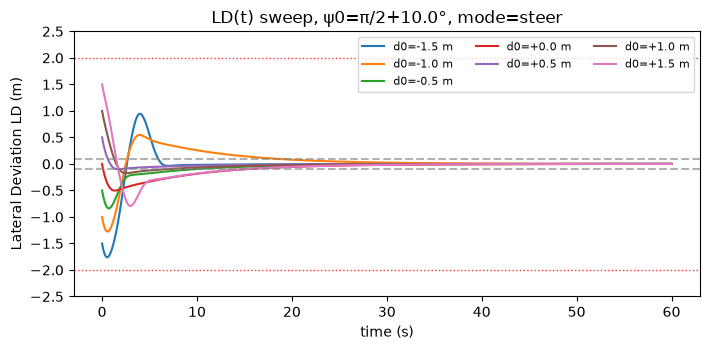

mode=steer, psi0 offset +10 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -1.760 |   0.946 |        no |              5.9 s | 0
  -1.0 |  -1.276 |   0.546 |        no |             18.1 s | 0
  -0.5 |  -0.839 |  -0.000 |        no |              9.7 s | 0
  +0.0 |  -0.503 |   0.000 |        no |             15.1 s | 0
  +0.5 |  -0.100 |   0.500 |        no |              1.8 s | 0
  +1.0 |  -0.174 |   1.000 |        no |              6.7 s | 0
  +1.5 |  -0.793 |   1.500 |        no |             14.9 s | 0
Runs that left the ±2 m lane: 0 of 7



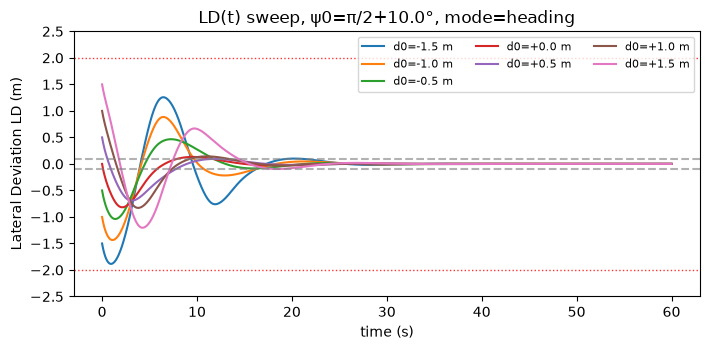

mode=heading, psi0 offset +10 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -1.885 |   1.257 |        no |             20.6 s | 0
  -1.0 |  -1.435 |   0.885 |        no |             16.1 s | 0
  -0.5 |  -1.038 |   0.466 |        no |             11.7 s | 0
  +0.0 |  -0.818 |   0.132 |        no |             11.5 s | 0
  +0.5 |  -0.694 |   0.500 |        no |              7.7 s | 0
  +1.0 |  -0.830 |   1.000 |        no |             13.2 s | 0
  +1.5 |  -1.204 |   1.500 |        no |             14.3 s | 0
Runs that left the ±2 m lane: 0 of 7



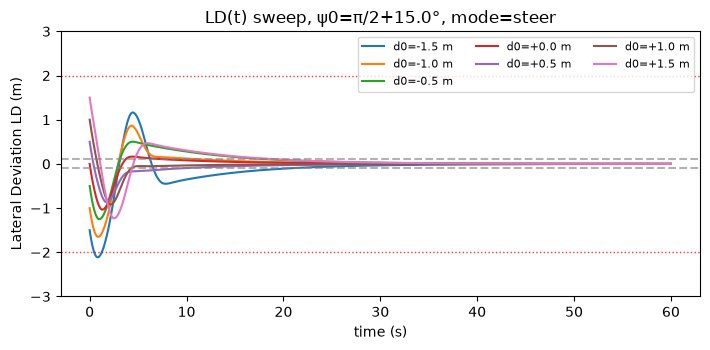

mode=steer, psi0 offset +15 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -2.113 |   1.164 |       YES |             20.6 s | 0
  -1.0 |  -1.651 |   0.866 |        no |             11.5 s | 0
  -0.5 |  -1.252 |   0.502 |        no |             18.8 s | 0
  +0.0 |  -1.034 |   0.165 |        no |              8.1 s | 0
  +0.5 |  -0.865 |   0.500 |        no |              9.4 s | 0
  +1.0 |  -0.918 |   1.000 |        no |              4.3 s | 0
  +1.5 |  -1.231 |   1.500 |        no |             19.5 s | 0
Runs that left the ±2 m lane: 1 of 7



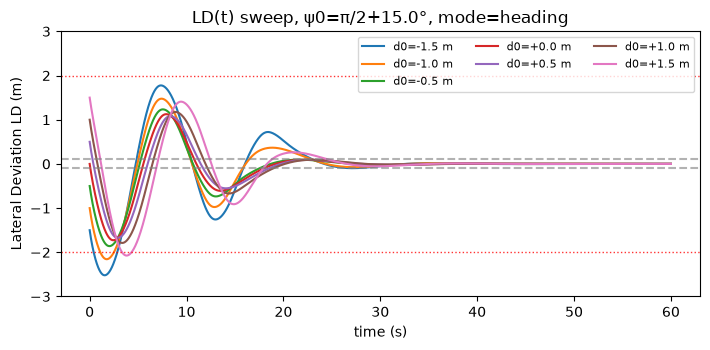

mode=heading, psi0 offset +15 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -2.520 |   1.776 |       YES |             23.0 s | 0
  -1.0 |  -2.156 |   1.476 |       YES |             22.9 s | 0
  -0.5 |  -1.860 |   1.234 |        no |             17.5 s | 0
  +0.0 |  -1.727 |   1.125 |        no |             18.0 s | 0
  +0.5 |  -1.674 |   1.082 |        no |             18.5 s | 0
  +1.0 |  -1.788 |   1.176 |        no |             19.0 s | 0
  +1.5 |  -2.074 |   1.500 |       YES |             24.6 s | 0
Runs that left the ±2 m lane: 3 of 7



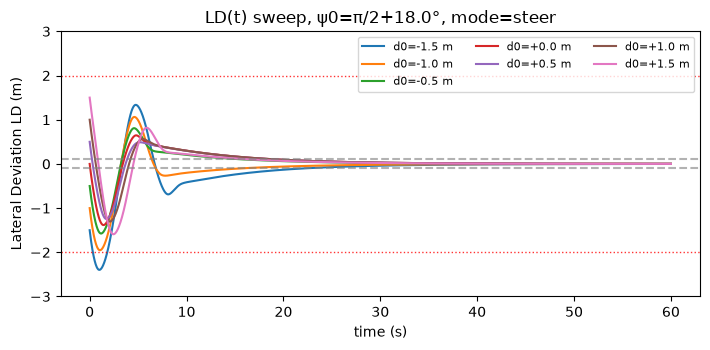

mode=steer, psi0 offset +18 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -2.397 |   1.336 |       YES |             22.2 s | 0
  -1.0 |  -1.953 |   1.063 |        no |             15.7 s | 0
  -0.5 |  -1.575 |   0.808 |        no |             16.0 s | 0
  +0.0 |  -1.383 |   0.647 |        no |             19.4 s | 0
  +0.5 |  -1.246 |   0.500 |        no |             19.3 s | 0
  +1.0 |  -1.305 |   1.000 |        no |             19.4 s | 0
  +1.5 |  -1.591 |   1.500 |        no |             16.7 s | 0
Runs that left the ±2 m lane: 1 of 7



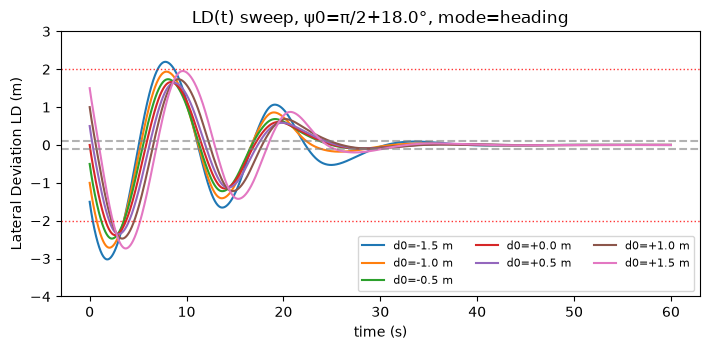

mode=heading, psi0 offset +18 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -3.021 |   2.195 |       YES |             29.4 s | 0
  -1.0 |  -2.712 |   1.936 |       YES |             28.6 s | 0
  -0.5 |  -2.471 |   1.736 |       YES |             23.8 s | 0
  +0.0 |  -2.379 |   1.660 |       YES |             24.0 s | 0
  +0.5 |  -2.354 |   1.639 |       YES |             24.4 s | 0
  +1.0 |  -2.471 |   1.736 |       YES |             24.8 s | 0
  +1.5 |  -2.732 |   1.952 |       YES |             30.3 s | 0
Runs that left the ±2 m lane: 7 of 7



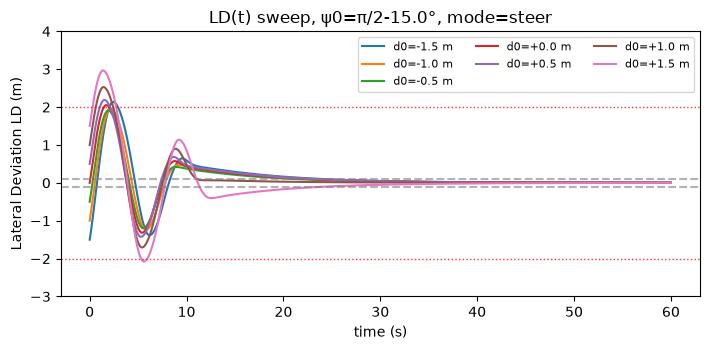

mode=steer, psi0 offset -15 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -1.500 |   2.135 |       YES |             24.1 s | 0
  -1.0 |  -1.238 |   1.957 |        no |             23.1 s | 0
  -0.5 |  -1.199 |   1.909 |        no |             21.4 s | 0
  +0.0 |  -1.316 |   2.052 |       YES |             22.6 s | 0
  +0.5 |  -1.426 |   2.188 |       YES |             23.3 s | 0
  +1.0 |  -1.706 |   2.528 |       YES |             11.1 s | 0
  +1.5 |  -2.076 |   2.966 |       YES |             24.3 s | 0
Runs that left the ±2 m lane: 5 of 7



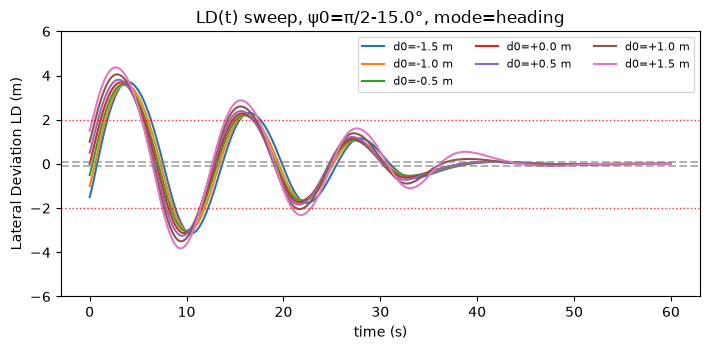

mode=heading, psi0 offset -15 deg, R=15 m, 60 s
d0 [m] |  min LD |  max LD | left lane | settle |LD|<=0.1 m | fallbacks
  -1.5 |  -3.156 |   3.716 |       YES |             38.0 s | 0
  -1.0 |  -3.051 |   3.613 |       YES |             37.7 s | 0
  -0.5 |  -3.033 |   3.595 |       YES |             37.4 s | 0
  +0.0 |  -3.129 |   3.690 |       YES |             37.2 s | 0
  +0.5 |  -3.253 |   3.811 |       YES |             37.2 s | 0
  +1.0 |  -3.501 |   4.054 |       YES |             42.4 s | 0
  +1.5 |  -3.822 |   4.366 |       YES |             43.3 s | 0
Runs that left the ±2 m lane: 7 of 7



In [5]:
if __name__ == "__main__":
    cfg = Config(R=15.0, t_final=60.0)   # all settings in one place
    d_vals = [-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5]

    # Positive offsets point the car toward the centre, the negative one points it outward.
    for psi_off in [10.0, 15.0, 18.0, -15.0]:
        plot_ld_sweep(cfg, d_vals, psi_off_deg=psi_off, mode="steer",   trim_first_s=0.0)
        plot_ld_sweep(cfg, d_vals, psi_off_deg=psi_off, mode="heading", trim_first_s=0.0)

## Is the Steer vs Heading comparison fair?

The two modes use different output gains (1.0 and 0.25), so this cell swaps them and also runs steer mode with the angle input switched off.

In [6]:
# ============================ Is the Steer vs Heading comparison fair? ============================
# The two modes differ in more than the angle signal: the fuzzy output is multiplied by
# sc_gain_steer = 1.0 in steer mode but by sc_gain_heading = 0.25 in heading mode.
# Swap the gains, and switch the angle input off in steer mode, to see what drives the difference.
if __name__ == "__main__":
    base = Config()   # R = 20 m, default start (LD = +1.5 m, tangent heading, wheels straight)

    def summary(label, cfg_run, zero_angle=False):
        ctrl_run = RoundaboutFuzzyController(cfg_run)
        ensure_built_for_current_op(ctrl_run, cfg_run)
        if zero_angle:   # feed ANG = 0 at every step
            original = ctrl_run.infer
            ctrl_run.infer = lambda ld, ldr, ang, di: original(ld, ldr, 0.0, di)
        r = simulate_roundabout(ctrl_run, cfg_run)
        print(f"{label:<34} | {np.sqrt(np.mean(r['ld']**2)):11.3f} | {r['ld'].min():10.3f} | "
              f"{fmt_time(settling_time(r)):>18} | {np.abs(r['sc']).max():13.2f}")

    print(f"{'run':<34} | {'RMS|LD| [m]':>11} | {'min LD [m]':>10} | {'settle |LD|<=0.1 m':>18} | {'max|SC| [deg]':>13}")
    summary("steer,   gain 1.0  (default)", dataclass_replace(base, error_mode="steer"))
    summary("heading, gain 0.25 (default)", dataclass_replace(base, error_mode="heading"))
    summary("steer,   gain 0.25", dataclass_replace(base, error_mode="steer", sc_gain_steer=0.25))
    summary("heading, gain 1.0", dataclass_replace(base, error_mode="heading", sc_gain_heading=1.0))
    summary("steer,   gain 1.0, ANG input = 0", dataclass_replace(base, error_mode="steer"), zero_angle=True)

run                                | RMS|LD| [m] | min LD [m] | settle |LD|<=0.1 m | max|SC| [deg]


steer,   gain 1.0  (default)       |       0.331 |     -0.739 |             29.4 s |          4.64


heading, gain 0.25 (default)       |       0.427 |     -0.966 |             19.7 s |          1.42


steer,   gain 0.25                 |       0.425 |     -0.960 |             19.6 s |          1.42


heading, gain 1.0                  |       0.335 |     -0.751 |             30.0 s |          4.76


steer,   gain 1.0, ANG input = 0   |       0.337 |     -0.751 |             30.0 s |          4.84
